# Are adult heights approximately normally distributed?

**A normal distribution provides a good descriptive approximation to adult heights within sex in these data.** Pooling men and women produces a flatter distribution.

This notebook analyzes measured adult standing heights from **CDC/NCHS NHANES 2017–2018**. It contains the data preparation, calculations, figures, and sensitivity checks behind the report. The main sample contains **5,185 adults aged 20 or older**. 

## 1. Data and reproducibility

NHANES heights were measured by trained health technicians. The CDC documentation recommends accounting for the survey sampling design.

| File | Contents | Documentation | Download |
|---|---|---|---|
| `BMX_J.xpt` | Measured height and measurement comments | [CDC height measurements](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.htm) | [XPT](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BMX_J.xpt) |
| `DEMO_J.xpt` | Age, sex, examination status, and survey sampling factors | [CDC demographics](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm) | [XPT](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.xpt) |

Both raw files are included in the neighboring `data/` directory. Select **Run All** to reproduce the analysis; no network connection is needed. The notebook works from its own directory or the repository root. It requires Python, NumPy, pandas, SciPy, Matplotlib, and a Jupyter Python kernel.
The notebook is self-contained apart from these two data files.

In [7]:
from pathlib import Path
import hashlib
import os
import platform
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "height-mpl"))

import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

candidates = [Path.cwd(), Path.cwd() / "analysis/height_normality"]
BASE = next((p for p in candidates if (p / "data/BMX_J.xpt").exists()), None)
if BASE is None:
    raise FileNotFoundError("Run from the notebook directory or repository root, with the data/ files present.")


We restrict the data to **adults aged 20+** and join the two files **one-to-one on `SEQN`**, the public respondent identifier. Height is `BMXHT` in centimeters. Age is `RIDAGEYR` at screening, and male/female groups are `RIAGENDR = 1/2`, respectively. `WTMEC2YR` is a survey sampling factor: it indicates how many people each participant represents. It corrects for unequal selection and survey nonresponse.

We load only the fields needed below and retain nonmissing heights with positive sampling factors. No height extremes are trimmed. The primary analysis retains height-measurement comments (`BMIHT`).

In [8]:
demo = pd.read_sas(BASE / "data/DEMO_J.xpt", format="xport")[
    ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDSTATR", "WTMEC2YR"]
]
demo = demo.loc[demo.RIDAGEYR.ge(20)].copy()
measurements = pd.read_sas(BASE / "data/BMX_J.xpt", format="xport")[
    ["SEQN", "BMXHT", "BMIHT"]
]
measurements = measurements.loc[measurements.SEQN.isin(demo.SEQN)].copy()
merged = demo.merge(measurements, on="SEQN", how="left", validate="one_to_one")

valid = merged.BMXHT.notna() & merged.WTMEC2YR.gt(0)
adults = merged.loc[valid].copy()
young = adults.loc[adults.RIDAGEYR.le(39)].copy()

assert adults.BMXHT.gt(0).all()
assert adults.RIDAGEYR.ge(20).all()
assert adults.RIAGENDR.isin([1, 2]).all()

groups = {
    "Adults 20+, pooled": adults,
    "Men 20+": adults.loc[adults.RIAGENDR.eq(1)],
    "Women 20+": adults.loc[adults.RIAGENDR.eq(2)],
    "Ages 20-39, pooled": young,
    "Men 20-39": young.loc[young.RIAGENDR.eq(1)],
    "Women 20-39": young.loc[young.RIAGENDR.eq(2)],
}
adult_names = list(groups)[:3]

sample_flow = pd.Series({
    "Demographic records, adults 20+": len(demo),
    "Height-measurement records, adults 20+": len(measurements),
    "Examined adults 20+": int(merged.RIDSTATR.eq(2).sum()),
    "Examined adults with missing height": int((merged.RIDSTATR.eq(2) & merged.BMXHT.isna()).sum()),
    "Analysis sample, adults 20+": len(adults),
}, name="Count").to_frame()
display(sample_flow)

,Count
"Demographic records, adults 20+",5569
"Height-measurement records, adults 20+",5265
Examined adults 20+,5265
Examined adults with missing height,80
"Analysis sample, adults 20+",5185


## 2. How normality is assessed

Within each group, let $h_i$ be height and let $a_i$ be the survey sampling factor normalized to sum to one. Fit a normal distribution using

$$\widehat\mu = \sum_i a_i h_i, \qquad
\widehat\sigma = \sqrt{\sum_i a_i(h_i-\widehat\mu)^2}.$$

Here $\widehat\sigma$ describes the spread of heights.

We compare histograms adjusted for survey sampling and Q–Q plots with the fitted normal, and compute:

In [9]:
def empirical_distribution(frame):
    """Aggregate ties before evaluating both sides of empirical CDF jumps."""
    x = frame.BMXHT.to_numpy()
    shares = frame.WTMEC2YR.to_numpy()
    shares = shares / shares.sum()
    order = np.argsort(x)
    heights, first = np.unique(x[order], return_index=True)
    masses = np.add.reduceat(shares[order], first)
    cumulative = np.cumsum(masses)
    return heights, masses, cumulative


def cdf_distance(frame, cdf):
    heights, masses, cumulative = empirical_distribution(frame)
    fitted = cdf(heights)
    return float(np.max(np.maximum(
        np.abs(cumulative - fitted),
        np.abs(cumulative - masses - fitted),
    )))


def summarize(frame):
    x = frame.BMXHT.to_numpy()
    shares = frame.WTMEC2YR.to_numpy()
    shares = shares / shares.sum()
    mean = float(np.sum(shares * x))
    sd = float(np.sqrt(np.sum(shares * (x - mean) ** 2)))
    z = (x - mean) / sd
    heights, _, cumulative = empirical_distribution(frame)
    probabilities = np.array([.01, .025, .05, .5, .95, .975, .99])
    observed = heights[np.searchsorted(cumulative, probabilities)]
    fitted = norm.ppf(probabilities, loc=mean, scale=sd)
    return {
        "n": len(frame),
        "mean_cm": mean,
        "sd_cm": sd,
        "skewness": float(np.sum(shares * z ** 3)),
        "excess_kurtosis": float(np.sum(shares * z ** 4) - 3),
        "within_1_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 1])),
        "within_2_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 2])),
        "within_3_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 3])),
        "max_cdf_gap": cdf_distance(frame, lambda h: norm.cdf(h, mean, sd)),
        "height_comment_count": int(frame.BMIHT.notna().sum()),
        "quantiles": [
            {"probability": float(p), "observed_cm": float(o), "normal_cm": float(f)}
            for p, o, f in zip(probabilities, observed, fitted)
        ],
    }

In [10]:
results = {name: summarize(frame) for name, frame in groups.items()}

def summary_table(names):
    table = pd.DataFrame({name: results[name] for name in names}).T
    table = table[["n", "mean_cm", "sd_cm", "within_1_sd_pct", "within_2_sd_pct"]]
    table.columns = ["n", "Mean (cm)", "SD (cm)", "Within 1 SD (%)", "Within 2 SD (%)"]
    return table.style.format({
        "n": "{:,.0f}", "Mean (cm)": "{:.2f}", "SD (cm)": "{:.2f}",
        "Within 1 SD (%)": "{:.2f}", "Within 2 SD (%)": "{:.2f}",
    })

display(summary_table(adult_names))


,n,Mean (cm),SD (cm),Within 1 SD (%),Within 2 SD (%)
"Adults 20+, pooled","5,185",167.86,10.04,65.15,96.63
Men 20+,"2,500",175.21,7.39,68.40,95.26
Women 20+,"2,685",161.05,6.88,67.94,95.06


In [11]:
male, female = results["Men 20+"], results["Women 20+"]
display(Markdown(
    "The fitted adult distributions, with height in centimeters, are approximately\n\n"
    rf"$$H_{{\mathrm{{men}}}} \approx \mathcal{{N}}({male['mean_cm']:.2f},\;{male['sd_cm']:.2f}^2),"
    rf"\qquad H_{{\mathrm{{women}}}} \approx \mathcal{{N}}({female['mean_cm']:.2f},\;{female['sd_cm']:.2f}^2).$$"
    "\n\nThe second argument is the **variance**. "
    f"The proportions within two SDs are {male['within_2_sd_pct']:.2f}% and "
    f"{female['within_2_sd_pct']:.2f}%, close to the normal benchmark of 95.45%. "
))

The fitted adult distributions, with height in centimeters, are approximately

$$H_{\mathrm{men}} \approx \mathcal{N}(175.21,\;7.39^2),\qquad H_{\mathrm{women}} \approx \mathcal{N}(161.05,\;6.88^2).$$

The second argument is the **variance**. The proportions within two SDs are 95.26% and 95.06%, close to the normal benchmark of 95.45%. 

## 3. Histograms and normal Q–Q plots

The upper panels compare height densities adjusted for survey sampling with fitted normals. In the lower panels, each distinct observed height is plotted against the fitted normal quantile at the **sampling-adjusted midpoint** of its empirical CDF jump. Every observed height is included. Points near the orange diagonal support the normal approximation; tail departures remain visible.

For pooled adults, the green dashed curve is a mixture of the separately fitted male and female normals. Its mixing proportions are the groups' shares of the summed survey sampling factors.

In [12]:
male_share = float(groups["Men 20+"].WTMEC2YR.sum() / adults.WTMEC2YR.sum())

def mixture(x, cumulative=False):
    function = norm.cdf if cumulative else norm.pdf
    return (male_share * function(x, male["mean_cm"], male["sd_cm"])
            + (1 - male_share) * function(x, female["mean_cm"], female["sd_cm"]))

COLORS = ["#657a8c", "#327ca4", "#9a607d"]
NORMAL_COLOR = "#c65e28"



def draw_pair(hist_ax, qq_ax, frame, stats, title, color, bins, mixture=None):
    x = frame.BMXHT.to_numpy()
    sampling_factors = frame.WTMEC2YR.to_numpy()
    mean, sd = stats["mean_cm"], stats["sd_cm"]
    hist_ax.hist(x, bins=bins, weights=sampling_factors, density=True,
                 color=color, alpha=.72, edgecolor="white", linewidth=.7,
                 label="Measured heights")
    grid = np.linspace(bins[0], bins[-1], 600)
    hist_ax.plot(grid, norm.pdf(grid, mean, sd), color=NORMAL_COLOR,
                 linewidth=2.2, label="Fitted normal")
    if mixture is not None:
        hist_ax.plot(grid, mixture(grid), color="#257a59", linewidth=2,
                     linestyle="--", label="Mixture of sex-specific normals")
    hist_ax.set_title(title, loc="left", fontsize=13, weight="bold", pad=10)
    hist_ax.text(.03, .96,
                 f"n = {stats['n']:,}\nMean {mean:.1f} cm | SD {sd:.1f} cm",
                 transform=hist_ax.transAxes, va="top", fontsize=9,
                 bbox={"facecolor": "white", "alpha": .86, "edgecolor": "none", "pad": 3})
    hist_ax.set_xlabel("Height (cm)")
    hist_ax.set_ylabel("Survey-adjusted density")
    hist_ax.set_xlim(bins[0], bins[-1])
    hist_ax.set_ylim(0, hist_ax.get_ylim()[1] * 1.26)

    heights, masses, cumulative = empirical_distribution(frame)
    # Sampling-adjusted midpoint positions; every distinct height is shown.
    probabilities = np.clip(cumulative - masses / 2, 1e-12, 1 - 1e-12)
    expected = norm.ppf(probabilities, loc=mean, scale=sd)
    qq_ax.scatter(expected, heights, s=8, color=color, alpha=.7, linewidths=0)
    low = min(expected.min(), heights.min()) - 2
    high = max(expected.max(), heights.max()) + 2
    qq_ax.plot([low, high], [low, high], color=NORMAL_COLOR, linewidth=1.6)
    qq_ax.set(xlim=(low, high), ylim=(low, high),
              xlabel="Fitted normal quantile (cm)", ylabel="Observed height (cm)")
    qq_ax.set_title("Normal Q–Q plot", fontsize=11, loc="left")
    qq_ax.text(.04, .95,
               f"Max CDF gap: {100 * stats['max_cdf_gap']:.1f} percentage points",
               transform=qq_ax.transAxes, fontsize=9, va="top")
    for ax in (hist_ax, qq_ax):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#dedede", linewidth=.5, alpha=.7)
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=9)

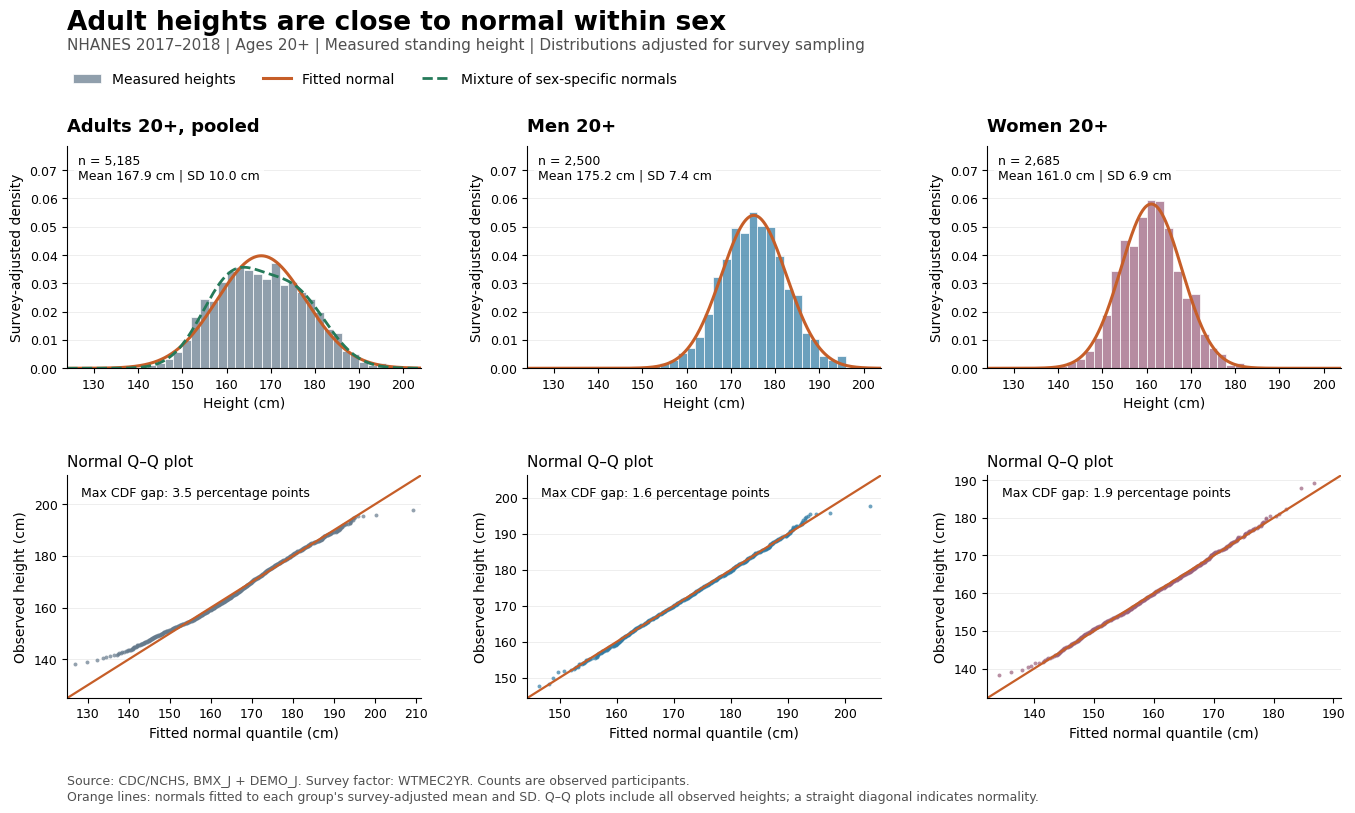

In [13]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
fig.suptitle("Adult heights are close to normal within sex", x=.07,
             ha="left", fontsize=19, weight="bold", y=.97)
fig.text(.07, .923, "NHANES 2017–2018 | Ages 20+ | Measured standing height | Distributions adjusted for survey sampling",
         fontsize=11, color="#505050")
for column, name in enumerate(adult_names):
    draw_pair(axes[0, column], axes[1, column], groups[name], results[name],
              name, COLORS[column], np.arange(124, 206, 2),
              mixture=mixture if column == 0 else None)
# Shared scales make the adult histograms comparable.
ymax = max(ax.get_ylim()[1] for ax in axes[0])
for ax in axes[0]:
    ax.set_ylim(0, ymax)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower left", bbox_to_anchor=(.065, .865),
           ncol=3, frameon=False, fontsize=10)
fig.subplots_adjust(left=.07, right=.98, bottom=.16, top=.81, wspace=.3, hspace=.48)
fig.text(.07, .04,
         "Source: CDC/NCHS, BMX_J + DEMO_J. Survey factor: WTMEC2YR. Counts are observed participants.\n"
         "Orange lines: normals fitted to each group's survey-adjusted mean and SD. Q–Q plots include all observed heights; a straight diagonal indicates normality.",
         fontsize=9, color="#505050")
plt.show()

In [14]:
mixture_gap = cdf_distance(adults, lambda h: mixture(h, cumulative=True))
display(Markdown(
    "**Interpretation.** The male and female histograms closely follow their fitted normals, "
    "and their Q–Q plots are nearly straight except for some tail deviations. "
    "The pooled distribution is flatter, consistent with its negative excess kurtosis.\n\n"
    f"The pooled single-normal CDF gap is {100 * results['Adults 20+, pooled']['max_cdf_gap']:.2f} "
    f"percentage points. The sex-specific normal mixture reduces it to {100 * mixture_gap:.2f} "
    f"points (male population share: {100 * male_share:.1f}%). "
    "The mixture has more parameters; this is an in-sample descriptive comparison."
))

**Interpretation.** The male and female histograms closely follow their fitted normals, and their Q–Q plots are nearly straight except for some tail deviations. The pooled distribution is flatter, consistent with its negative excess kurtosis.

The pooled single-normal CDF gap is 3.49 percentage points. The sex-specific normal mixture reduces it to 1.08 points (male population share: 48.1%). The mixture has more parameters; this is an in-sample descriptive comparison.

## 5. Conclusion and limits

- **Adult men and adult women separately:** a normal distribution is a useful approximation in this dataset, with small deviations in the tails.
- **Pooled adults:** a single normal is less accurate; the distribution is flatter, and a mixture of sex-specific normals follows it more closely.

**Reproducibility record.** 
These are descriptive results for US NHANES 2017–2018 data. The cell below records the raw-file checksums. Data attribution: CDC/NCHS, NHANES 2017–2018. Analysis code and figures follow this repository's CC BY-NC-SA 4.0 license.

In [15]:
for filename in ("BMX_J.xpt", "DEMO_J.xpt"):
    checksum = hashlib.sha256((BASE / "data" / filename).read_bytes()).hexdigest()
    print(f"{filename}: SHA256 {checksum}")

BMX_J.xpt: SHA256 8d675e42d8826ac98714b2c3dd4c5138a5e353fb4424f7eff5e6db4a01ce838a
DEMO_J.xpt: SHA256 c0b46e0345ea19404928656277c8b0d10b0cca348a9b2fe4fc3c67e8b7ee73ec
